In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

#                                               Steps for the Kmeans Algorithm:
```js
        1) Pick k centroid’s points randomly from the dataset and assign it to current_centroids.
        2) create an 1D array, y, with total_row_size of the dataset.
        3) Traverse each Point|Row and update it’s cluster_group_no with a loop.
        4) Move|update centroids.
        5) Repeat steps 3 and 4 until the previous_centroids and current_centroids are not same.
```

#                                                   Dataset Creation and splitting

In [ ]:
customer = ( pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\10. K Means Clustering\Dataset\Mall_Customers.csv")
            .loc[:, ['Age', 'Annual Income (k$)']] # The reason to take 2 columns so we can visualize easily. The below
           )                                       # custom KMeans_clustering works for number of columns.
print(customer)

x_train, x_test = train_test_split(customer, test_size = 0.2, random_state = 42) # (160, 2), (40, 2) shapes dataframe.

     Age  Annual Income (k$)
0     19                  15
1     21                  15
2     20                  16
3     23                  16
4     31                  17
..   ...                 ...
195   35                 120
196   45                 126
197   32                 126
198   32                 137
199   30                 137

[200 rows x 2 columns]


#                                       Creating our custom KMeans_clustering class.

In [ ]:
class KMeans_clustering:
    def __init__(self, n_clusters = 2):
        self.cluster_centers_ = None # centroids.
        self.n_clusters = n_clusters
    
    def fit_predict(self, X: pd.DataFrame):
        cur_centroids = X.sample(n = self.n_clusters, random_state = 42).astype('float') # each row denoting the centroid of a cluster.
        cur_centroids.index = np.arange(0, self.n_clusters) # (cur_centroids - cur_rows) returns faulty output if indexes are not same.

        prev_centroids = None
        y = np.full(shape = X.shape[0], fill_value = -1)
        
        while not cur_centroids.equals(prev_centroids):
            for i in range(0, X.shape[0]):
                cur_rows = X.iloc[i:i+1] .iloc[[0] * self.n_clusters] # repeating the single row self.n_clusters times in datasframe shape,
                                                                # so we can subtract that single row from all the centroids.
                cur_rows.index = cur_centroids.index # same as np.arange(0, self.n_clusters).

                # euclidean = All the clusters euclidean distance from the current_point | cur_row
                euclidean = (cur_centroids - cur_rows).pow(2, axis=1).sum(axis=1).pow(0.5)
                y[i] = euclidean.argmin() # y[i] denoting the cluster_no of the first input row.
            
            prev_centroids = cur_centroids
            for centroid_no in range(self.n_clusters):
                cur_centroids.iloc[centroid_no] = X.loc[y == centroid_no].mean(axis = 0)
        
        self.cluster_centers_ = cur_centroids
        return y
    
    def predict(self, X: pd.DataFrame):
        y = np.full(shape = X.shape[0], fill_value = -1)
        
        for i in range(0, X.shape[0]):
            cur_rows = X.iloc[i:i+1] .iloc[[0] * self.n_clusters] # repeating the single row self.n_clusters times in datasframe shape,
                                                            # so we can subtract that single row from all the centroids.
            cur_rows.index = self.cluster_centers_.index # same as np.arange(0, self.n_clusters).

            # euclidean = All the clusters euclidean distance from the current_point | cur_row
            euclidean = (self.cluster_centers_ - cur_rows).pow(2, axis=1).sum(axis=1).pow(0.5)
            y[i] = euclidean.argmin() # y[i] denoting the cluster_no of the first input row.
        
        return y

#                                       Creating an object of our custom kmeans_clustering class.

In [ ]:
kmean = KMeans_clustering(n_clusters = 4)
y = kmean.fit_predict(X= x_train)
centroids = kmean.cluster_centers_

print(f"x_train's 10 Rows with their corresponding cluster number :\n\n{x_train.assign(cluster_no = y).head(10)}.")

print(f"\nCentroids of clusters :\n\n{centroids}.")

x_train's 10 Rows with their corresponding cluster number :

     Age  Annual Income (k$)  cluster_no
79    49                  54           0
197   32                 126           3
38    36                  37           2
24    54                  28           0
122   40                  69           1
195   35                 120           3
29    23                  29           2
19    35                  23           0
143   32                  76           1
86    55                  57           0.

Centroids of clusters :

         Age  Annual Income (k$)
0  53.577778           41.133333
1  31.372549           73.352941
2  32.512195           40.756098
3  38.347826          105.826087.


#                                       Visualizing how kmean grouped the data on x_train data.

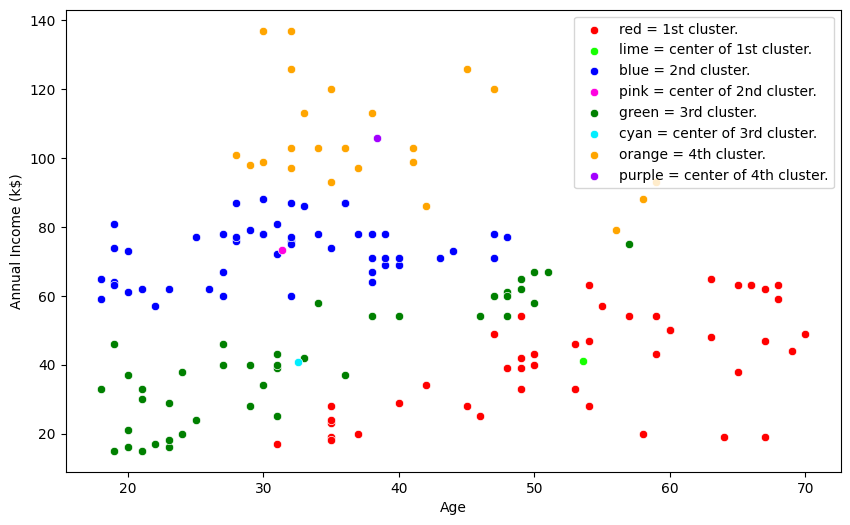

In [ ]:
plt.figure(figsize = (10, 6))
sns.scatterplot(data = x_train.loc[y == 0], x = 'Age', y = 'Annual Income (k$)', color = 'red') # 1st cluster group.
sns.scatterplot(x = [centroids.iloc[0, 0]], y = [centroids.iloc[0, 1]], color = "#16ff01") # centre of 1st cluster.

sns.scatterplot(data = x_train.loc[y == 1], x = 'Age', y = 'Annual Income (k$)', color = 'blue') # 2nd cluster group.
sns.scatterplot(x = [centroids.iloc[1, 0]], y = [centroids.iloc[1, 1]], color = "#ff02e0") # centre of 2nd cluster.

sns.scatterplot(data = x_train.loc[y == 2], x = 'Age', y = 'Annual Income (k$)', color = 'green') # 3rd cluster group.
sns.scatterplot(x = [centroids.iloc[2, 0]], y = [centroids.iloc[2, 1]], color = "#01eeff") # centre of 3rd cluster.

sns.scatterplot(data = x_train.loc[y == 3], x = 'Age', y = 'Annual Income (k$)', color = 'orange') # 4th cluster group.
sns.scatterplot(x = [centroids.iloc[3, 0]], y = [centroids.iloc[3, 1]], color = "#a200ff") # centre of 4th cluster.

plt.legend(['red = 1st cluster.', 'lime = center of 1st cluster.',
            'blue = 2nd cluster.', 'pink = center of 2nd cluster.', 
            'green = 3rd cluster.', 'cyan = center of 3rd cluster.',
            'orange = 4th cluster.', 'purple = center of 4th cluster.'])
plt.show()

#                             Predicting cluster_no on x_test data and visualize them on x_train dataset.

x_test's 10 Rows with their corresponding cluster number :

     Age  Annual Income (k$)  cluster_no
95    24                  60           1
15    22                  20           2
30    60                  30           0
158   34                  78           1
128   59                  71           1
115   19                  65           1
69    32                  48           2
170   40                  87           1
174   52                  88           3
45    24                  39           2.


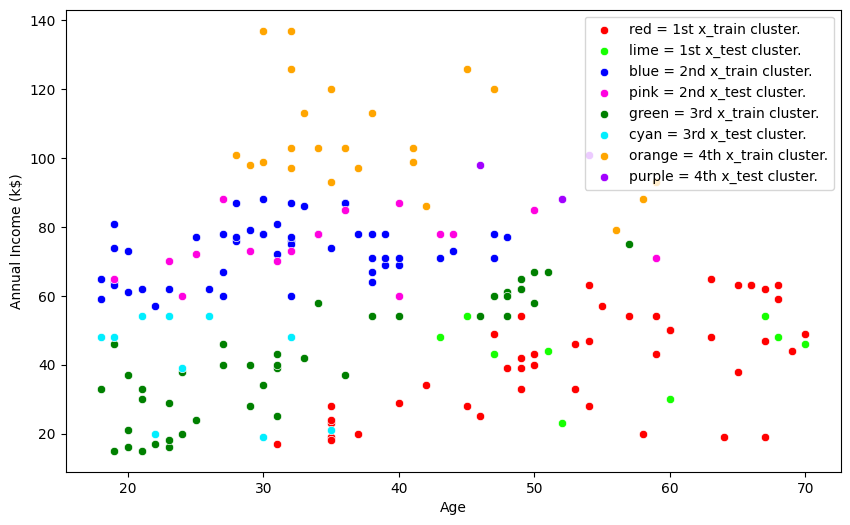

In [ ]:
y1 = kmean.predict(x_test)
print(f"x_test's 10 Rows with their corresponding cluster number :\n\n{x_test.assign(cluster_no = y1).head(10)}.")

# Now e.g., for the 1st cluster group we can check if their training and testing input values are really together or not.
# Similarly for the rest clusters.

plt.figure(figsize = (10, 6))
sns.scatterplot(data = x_train.loc[y == 0], x = 'Age', y = 'Annual Income (k$)', color = 'red') # 1st cluster group.
sns.scatterplot(data = x_test.loc[y1 == 0], x = 'Age', y = 'Annual Income (k$)', color = '#16ff01') # 1st cluster group.

sns.scatterplot(data = x_train.loc[y == 1], x = 'Age', y = 'Annual Income (k$)', color = 'blue') # 2nd cluster group.
sns.scatterplot(data = x_test.loc[y1 == 1], x = 'Age', y = 'Annual Income (k$)', color = '#ff02e0') # 1st cluster group.

sns.scatterplot(data = x_train.loc[y == 2], x = 'Age', y = 'Annual Income (k$)', color = 'green') # 3rd cluster group.
sns.scatterplot(data = x_test.loc[y1 == 2], x = 'Age', y = 'Annual Income (k$)', color = '#01eeff') # 1st cluster group.

sns.scatterplot(data = x_train.loc[y == 3], x = 'Age', y = 'Annual Income (k$)', color = 'orange') # 4th cluster group.
sns.scatterplot(data = x_test.loc[y1 == 3], x = 'Age', y = 'Annual Income (k$)', color = '#a200ff') # 1st cluster group.

plt.legend(['red = 1st x_train cluster.', 'lime = 1st x_test cluster.',
            'blue = 2nd x_train cluster.', 'pink = 2nd x_test cluster.', 
            'green = 3rd x_train cluster.', 'cyan = 3rd x_test cluster.',
            'orange = 4th x_train cluster.', 'purple = 4th x_test cluster.'])
plt.show()